# 20 · The equations of motion inside MuJoCo: M(q) v̇ + c(q, v) = τ + Jᵀf

In [1]:
import mujoco, mujoco_menagerie as mm, numpy as np, matplotlib.pyplot as plt

def full_M(model, data):
    M = np.zeros((model.nv, model.nv))
    mujoco.mj_fullM(model, data, M)
    return M

def panda_on_table():
    spec = mm.get("franka_emika_panda").spec("scene")
    b = spec.worldbody.add_body(name="box", pos=[0.5, 0, 0.05])
    b.add_freejoint()
    b.add_geom(type=mujoco.mjtGeom.mjGEOM_BOX, size=[0.05] * 3, rgba=[0.8, 0.3, 0.3, 1], mass=0.5)
    model = spec.compile()
    data = mujoco.MjData(model)
    mujoco.mj_resetDataKeyframe(model, data, 0)
    data.qpos[9:12] = [0.5, 0, 0.05]
    return model, data

In [2]:
model, data = panda_on_table()
rng = np.random.default_rng(0)
data.qvel[:7] = rng.normal(0, 0.5, 7)
data.ctrl[:7] = data.qpos[:7] + 0.1
for _ in range(200):
    mujoco.mj_step(model, data)
mujoco.mj_forward(model, data)
M = full_M(model, data)
lhs = M @ data.qacc + data.qfrc_bias
rhs = data.qfrc_passive + data.qfrc_actuator + data.qfrc_applied + data.qfrc_constraint
print("nv =", model.nv, "| active constraints:", data.nefc, "| contacts:", data.ncon)
print("max |M qacc + c - (tau + J^T f)| =", np.abs(lhs - rhs).max())
jtf = np.zeros(model.nv)
mujoco.mj_mulJacTVec(model, data, jtf, data.efc_force)
print("J^T f == qfrc_constraint:", np.allclose(jtf, data.qfrc_constraint))

nv = 15 | active constraints: 18 | contacts: 4
max |M qacc + c - (tau + J^T f)| = 1.942890293094024e-16
J^T f == qfrc_constraint: True


M symmetric: True | positive definite: True
eigenvalues of the arm block: [0.1067 0.1178 0.1248 0.1392 0.3824 3.0278 3.7057]


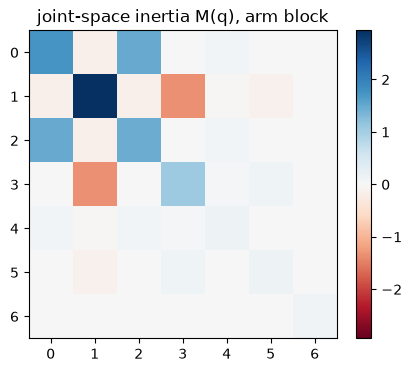

In [3]:
arm = M[:7, :7]
eig = np.linalg.eigvalsh(arm)
print("M symmetric:", np.allclose(arm, arm.T), "| positive definite:", (eig > 0).all())
print("eigenvalues of the arm block:", eig.round(4))
plt.figure(figsize=(5, 4)); plt.imshow(arm, cmap="RdBu", vmin=-np.abs(arm).max(), vmax=np.abs(arm).max()); plt.colorbar()
plt.title("joint-space inertia M(q), arm block"); plt.show()

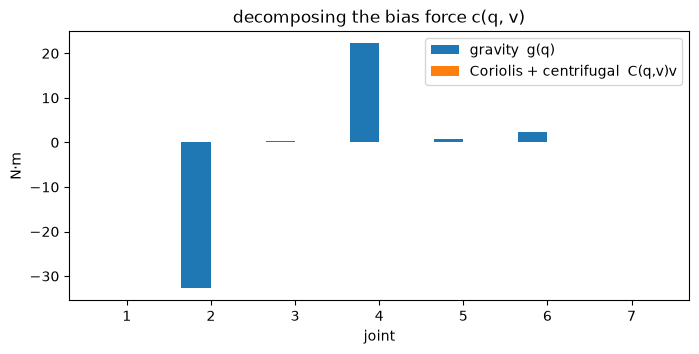

In [4]:
q_save, v_save = data.qpos.copy(), data.qvel.copy()
data.qvel[:] = 0; mujoco.mj_forward(model, data); gravity = data.qfrc_bias[:7].copy()
data.qvel[:] = v_save; mujoco.mj_forward(model, data); total = data.qfrc_bias[:7].copy()
plt.figure(figsize=(8, 3.5))
w = 0.35; x = np.arange(1, 8)
plt.bar(x - w / 2, gravity, w, label="gravity  g(q)"); plt.bar(x + w / 2, total - gravity, w, label="Coriolis + centrifugal  C(q,v)v")
plt.xlabel("joint"); plt.ylabel("N·m"); plt.legend(); plt.title("decomposing the bias force c(q, v)"); plt.show()

In [5]:
data.qacc[:] = 0
data.qacc[:7] = rng.normal(0, 1, 7)
data.qvel[:] = 0; data.qvel[:7] = rng.normal(0, 0.5, 7)
mujoco.mj_inverse(model, data)
M = full_M(model, data)
manual = M @ data.qacc + data.qfrc_bias - data.qfrc_passive
print("mj_inverse == M qacc + c - passive (arm, no contacts on links):", np.allclose(data.qfrc_inverse[:7], manual[:7], atol=1e-6))

mj_inverse == M qacc + c - passive (arm, no contacts on links): True


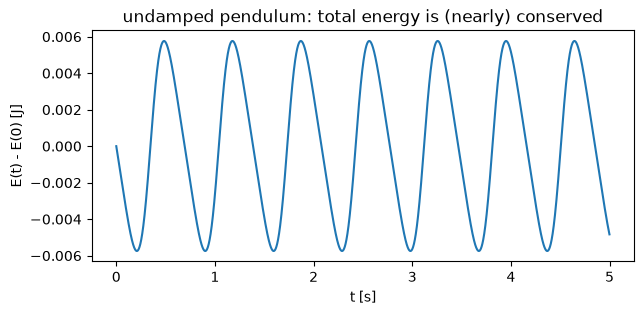

In [6]:
xml = """<mujoco><option timestep="0.001"><flag contact="disable"/></option>
<worldbody><body pos="0 0 1"><joint name="h" axis="0 1 0"/><geom type="capsule" fromto="0 0 0 .5 0 0" size=".02" mass="1"/></body></worldbody></mujoco>"""
pm = mujoco.MjModel.from_xml_string(xml); pd = mujoco.MjData(pm)
pm.opt.enableflags |= mujoco.mjtEnableBit.mjENBL_ENERGY
energy = []
while pd.time < 5:
    mujoco.mj_step(pm, pd); energy.append(pd.energy.sum())
plt.figure(figsize=(7, 3)); plt.plot(np.arange(len(energy)) * 1e-3, np.array(energy) - energy[0])
plt.xlabel("t [s]"); plt.ylabel("E(t) - E(0) [J]"); plt.title("undamped pendulum: total energy is (nearly) conserved"); plt.show()